In [ ]:
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import data

print("OpenCV", cv2.__version__)

MAX_KP   = 1000   # keep the top-N keypoints for every algorithm
RATIO    = 0.75   # Lowe's ratio test threshold
PIX_TOL  = 3.0    # correct match = lands within this many pixels of ground truth

OpenCV 4.14.0


These are the three knobs of the experiment. MAX_KP caps every algorithm at the same number of keypoints so none wins just by detecting more. RATIO controls how strict matching is: a match is kept only if the best candidate is clearly better than the second best. PIX_TOL defines how close a match has to land to the true location to count as correct.

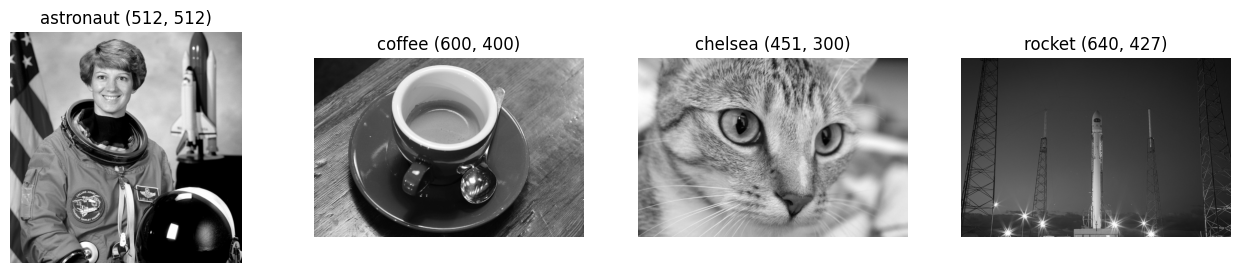

In [ ]:
rgb = {
    "astronaut": data.astronaut(),
    "coffee":    data.coffee(),
    "chelsea":   data.chelsea(),
    "rocket":    data.rocket(),
}
gray = {k: cv2.cvtColor(v, cv2.COLOR_RGB2GRAY) for k, v in rgb.items()}

fig, axes = plt.subplots(1, len(gray), figsize=(4 * len(gray), 3))
for ax, (name, im) in zip(axes, gray.items()):
    ax.imshow(im, cmap="gray"); ax.set_title(f"{name} {im.shape[::-1]}"); ax.axis("off")
plt.show()

This loads four images that ship with scikit-image and converts them to grayscale, since these descriptors work on intensity only. Using several images with different textures keeps the results from depending on one image.

In [ ]:
ALGOS = {
    "SIFT":  (cv2.SIFT_create(nfeatures=MAX_KP),  cv2.NORM_L2),
    "ORB":   (cv2.ORB_create(nfeatures=MAX_KP),   cv2.NORM_HAMMING),
    "BRISK": (cv2.BRISK_create(),                 cv2.NORM_HAMMING),
    "AKAZE": (cv2.AKAZE_create(),                 cv2.NORM_HAMMING),
}

def extract(algo, img):
    """Detect + describe. Keep top MAX_KP keypoints by response. Returns (kps, descs, ms)."""
    t = time.perf_counter()
    kps, des = algo.detectAndCompute(img, None)
    ms = (time.perf_counter() - t) * 1000
    if des is None or len(kps) == 0:
        return [], None, ms
    order = np.argsort([-k.response for k in kps])[:MAX_KP]
    return [kps[i] for i in order], des[order], ms

Each entry pairs an algorithm with the distance metric that suits its descriptor. SIFT produces float vectors, so it uses L2 distance. ORB, BRISK and AKAZE produce binary strings, so they use Hamming distance (the count of differing bits). extract runs detection and description together, times it, and keeps only the strongest MAX_KP keypoints so the comparison stays fair.

In [ ]:
def _to_H(M):
    return np.vstack([M, [0, 0, 1]]).astype(np.float64)

def t_rotation(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    c, s = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * s + w * c), int(h * c + w * s)   # enlarge canvas, no cropping
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh)), _to_H(M)

def t_scale(img, s):
    h, w = img.shape[:2]
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR
    out = cv2.resize(img, (round(w * s), round(h * s)), interpolation=interp)
    off = 0.5 * (s - 1)                               # pixel-centre convention of cv2.resize
    M = np.array([[s, 0, off], [0, s, off]], dtype=np.float64)
    return out, _to_H(M)

def t_blur(img, sigma):
    out = img.copy() if sigma == 0 else cv2.GaussianBlur(img, (0, 0), sigma)
    return out, np.eye(3)

def t_noise(img, sigma):
    rng = np.random.default_rng(0)
    out = np.clip(img + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)
    return out, np.eye(3)

def t_brightness(img, gain):
    out = np.clip(img.astype(np.float32) * gain, 0, 255).astype(np.uint8)
    return out, np.eye(3)

EXPERIMENTS = {
    "rotation (deg)":    (t_rotation,   [0, 15, 30, 45, 60, 90, 120, 150, 180]),
    "scale":             (t_scale,      [0.4, 0.5, 0.7, 1.0, 1.4, 2.0]),
    "blur (sigma)":      (t_blur,       [0, 1, 2, 3, 4, 6]),
    "noise (sigma)":     (t_noise,      [0, 5, 10, 20, 30, 40]),
    "brightness (gain)": (t_brightness, [0.3, 0.5, 0.75, 1.0, 1.5, 2.0]),
}

This is the core idea of the benchmark. Every function returns the transformed image and a 3x3 matrix H that maps original coordinates to transformed coordinates. That matrix is the ground truth, so we know exactly where every keypoint should end up.

Rotation and scale are geometric, so H is a real matrix. For rotation, the canvas is enlarged so no content is cropped.
Blur, noise and brightness are photometric, so no pixel moves and H is the identity.
EXPERIMENTS maps each test to its severity levels. Each one includes a "no change" level (0 degrees, scale 1.0, and so on) as a baseline.

In [ ]:
def match(norm, des1, des2):
    """kNN match with Lowe's ratio test."""
    if des1 is None or des2 is None or len(des1) < 2 or len(des2) < 2:
        return []
    knn = cv2.BFMatcher(norm).knnMatch(des1, des2, k=2)
    return [p[0] for p in knn if len(p) == 2 and p[0].distance < RATIO * p[1].distance]

def correctness(good, kps1, kps2, H):
    """Boolean array: is each match consistent with the ground-truth homography?"""
    if not good:
        return np.zeros(0, dtype=bool)
    p1 = np.float32([kps1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    proj = cv2.perspectiveTransform(p1, H).reshape(-1, 2)
    p2 = np.float32([kps2[m.trainIdx].pt for m in good])
    return np.linalg.norm(proj - p2, axis=1) < PIX_TOL

match finds the two nearest descriptors in image 2 for each descriptor in image 1 and keeps the match only if the best is clearly closer than the runner-up. This is Lowe's ratio test, and it filters out ambiguous matches.
correctness is the evaluation. It takes each matched keypoint in image 1, projects it through H to where it should be in image 2, and compares that to where the algorithm actually matched it. Within PIX_TOL pixels counts as correct.

In [ ]:
# Cache the original images' keypoints/descriptors (they don't change between experiments)
base = {(n, a): extract(algo, im) for n, im in gray.items() for a, (algo, _) in ALGOS.items()}

rows = []
for img_name, img in gray.items():
    for exp, (fn, params) in EXPERIMENTS.items():
        for p in params:
            warped, H = fn(img, p)
            for a, (algo, norm) in ALGOS.items():
                k1, d1, _ = base[(img_name, a)]
                k2, d2, _ = extract(algo, warped)
                good = match(norm, d1, d2)
                ok = correctness(good, k1, k2, H)
                rows.append(dict(
                    image=img_name, experiment=exp, param=p, algo=a,
                    n_kp=len(k2), n_matches=len(good), n_correct=int(ok.sum()),
                    precision=ok.mean() if len(ok) else 0.0,
                ))

df = pd.DataFrame(rows)
df.head()

,image,experiment,param,algo,n_kp,n_matches,n_correct,precision
0,astronaut,rotation (deg),0.0,SIFT,1000,1000,1000,1.000000
1,astronaut,rotation (deg),0.0,ORB,1000,1000,1000,1.000000
2,astronaut,rotation (deg),0.0,BRISK,1000,1000,1000,1.000000
3,astronaut,rotation (deg),0.0,AKAZE,870,870,870,1.000000
4,astronaut,rotation (deg),15.0,SIFT,1000,606,599,0.988449


This loops over every image, every transformation level and every algorithm. The original image is processed once and cached, and only the transformed version is processed each time. Each row records how many matches survived the ratio test, how many were correct, and the precision (correct / total). It takes a minute or two.

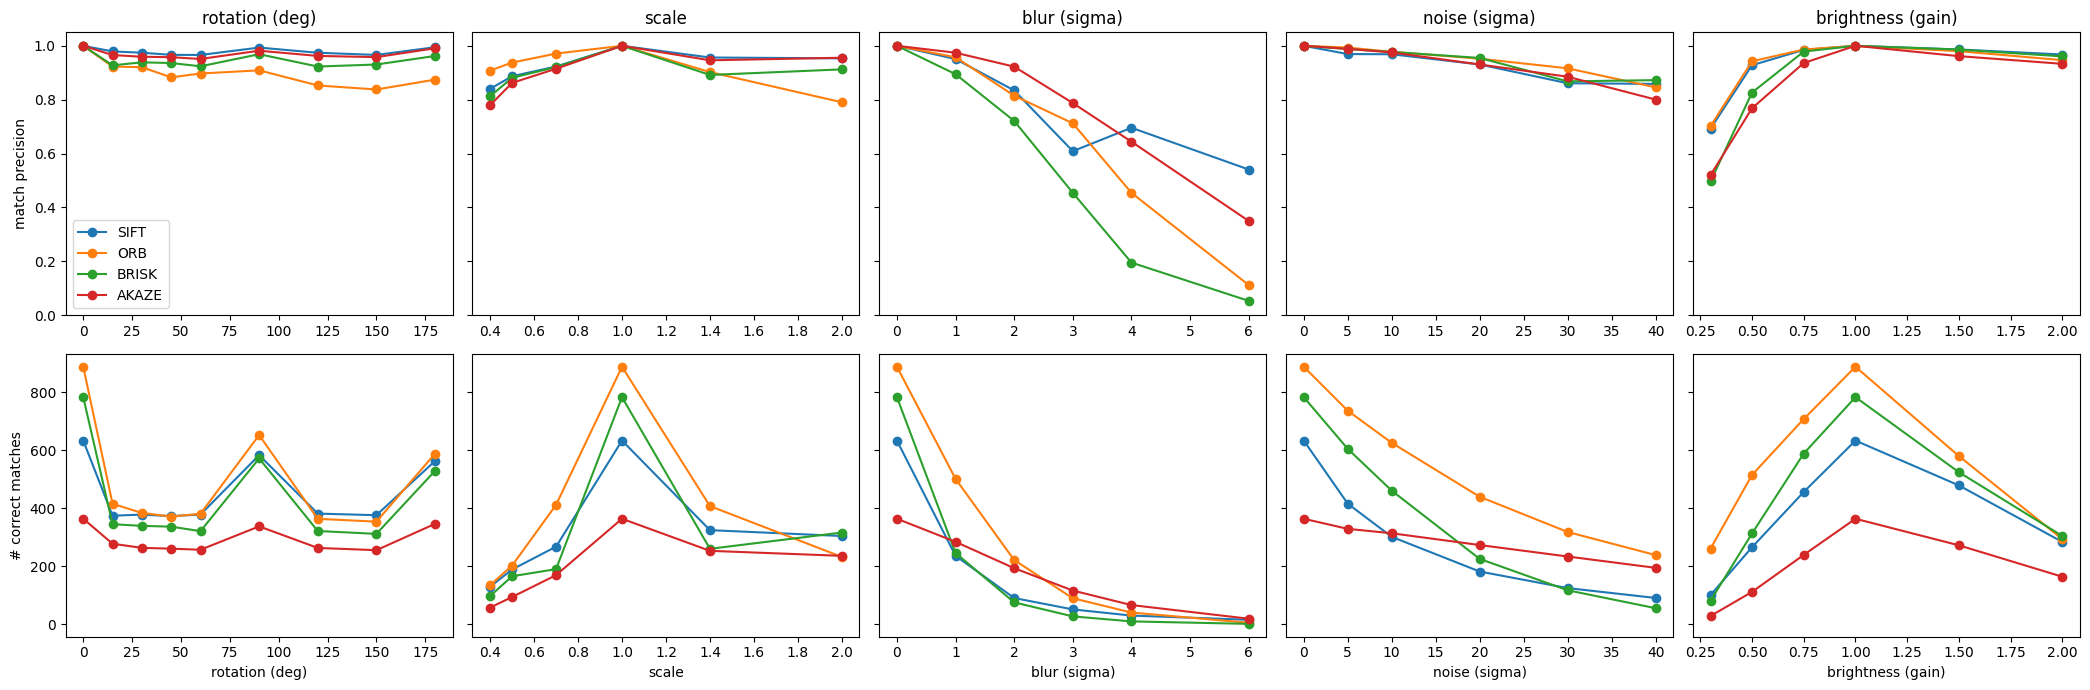

In [ ]:
summary = df.groupby(["experiment", "param", "algo"])[["precision", "n_correct"]].mean().reset_index()

fig, axes = plt.subplots(2, len(EXPERIMENTS), figsize=(4.2 * len(EXPERIMENTS), 7), sharey="row")
for j, exp in enumerate(EXPERIMENTS):
    sub = summary[summary.experiment == exp]
    for a in ALGOS:
        s = sub[sub.algo == a]
        axes[0, j].plot(s.param, s.precision, marker="o", label=a)
        axes[1, j].plot(s.param, s.n_correct, marker="o", label=a)
    axes[0, j].set_title(exp)
    axes[0, j].set_ylim(0, 1.05)
    axes[1, j].set_xlabel(exp)
axes[0, 0].set_ylabel("match precision")
axes[1, 0].set_ylabel("# correct matches")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

This averages over the four images and draws one column per transformation. The top row is precision, meaning how trustworthy the matches are. The bottom row is the number of correct matches, meaning how many you actually get. You need both, because an algorithm can have 100% precision on 2 matches and be useless.

In [ ]:
speed = []
for n, im in gray.items():
    for a, (algo, _) in ALGOS.items():
        ts = [extract(algo, im)[2] for _ in range(3)]
        speed.append(dict(algo=a, image=n, ms=np.mean(ts), n_kp=len(extract(algo, im)[0])))
speed = pd.DataFrame(speed)
speed.groupby("algo")[["ms", "n_kp"]].mean().round(1)

,ms,n_kp
algo,,
AKAZE,29.7,364.0
BRISK,30.9,784.2
ORB,7.2,887.5
SIFT,79.8,633.2


This times detection plus description per image, averaged over three runs. In my test run ORB was by far the fastest, at about 4 ms against roughly 60 ms for SIFT. Colab's CPU will give different absolute numbers, but the ordering should hold.

In [ ]:
def show_matches(img_name, exp, param, algo_name, max_draw=80):
    img = gray[img_name]
    fn, _ = EXPERIMENTS[exp]
    warped, H = fn(img, param)
    algo, norm = ALGOS[algo_name]
    k1, d1, _ = base[(img_name, algo_name)]
    k2, d2, _ = extract(algo, warped)
    good = match(norm, d1, d2)
    ok = correctness(good, k1, k2, H)
    right = [m for m, o in zip(good, ok) if o][:max_draw]
    wrong = [m for m, o in zip(good, ok) if not o][:max_draw]
    flags = cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    out = cv2.drawMatches(img, k1, warped, k2, wrong, None, matchColor=(255, 0, 0), flags=flags)
    out = cv2.drawMatches(img, k1, warped, k2, right, out, matchColor=(0, 255, 0),
                          flags=flags | cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG)
    plt.figure(figsize=(14, 6)); plt.imshow(out); plt.axis("off")
    plt.title(f"{algo_name} | {exp}={param} | {ok.sum()} correct / {len(ok)} matches")
    plt.show()


Always sanity-check a metric by eye. This draws correct matches in green and wrong ones in red for one chosen case. If the green lines don't run parallel under a pure rotation or scale, something is off in the ground-truth matrix. You can change the arguments to inspect any combination,

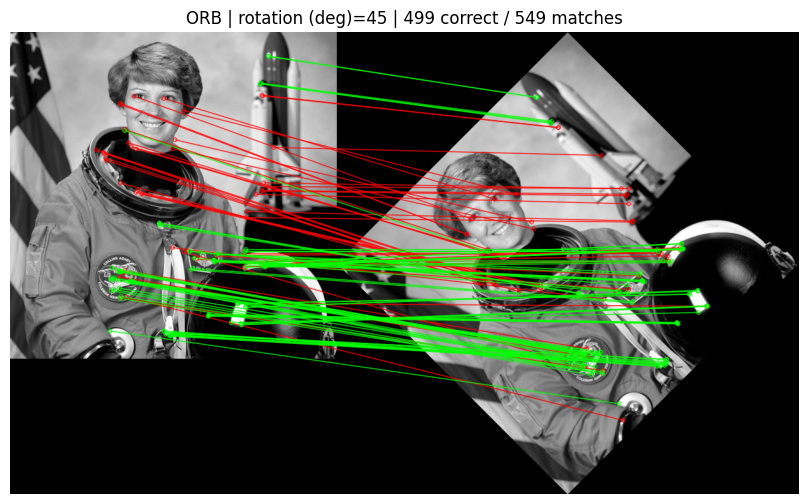

In [ ]:
show_matches("astronaut", "rotation (deg)", 45, "ORB")

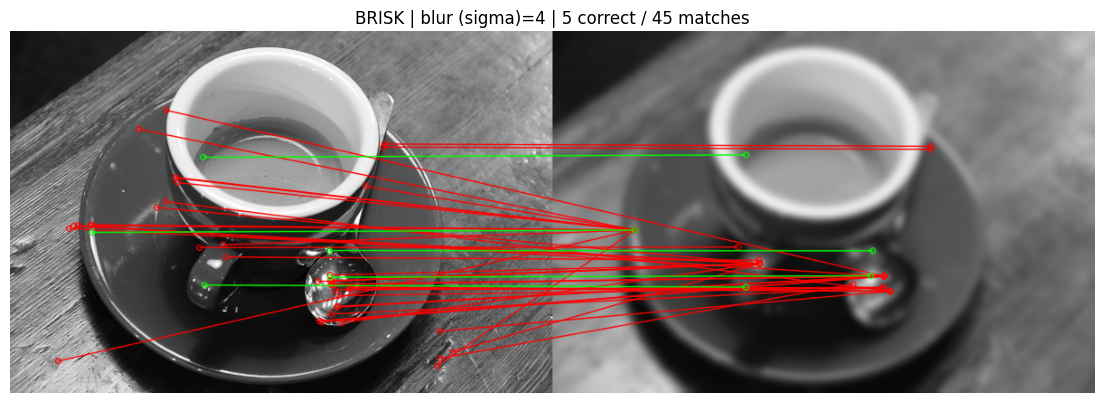

In [ ]:
show_matches("coffee","blur (sigma)", 4, "BRISK")

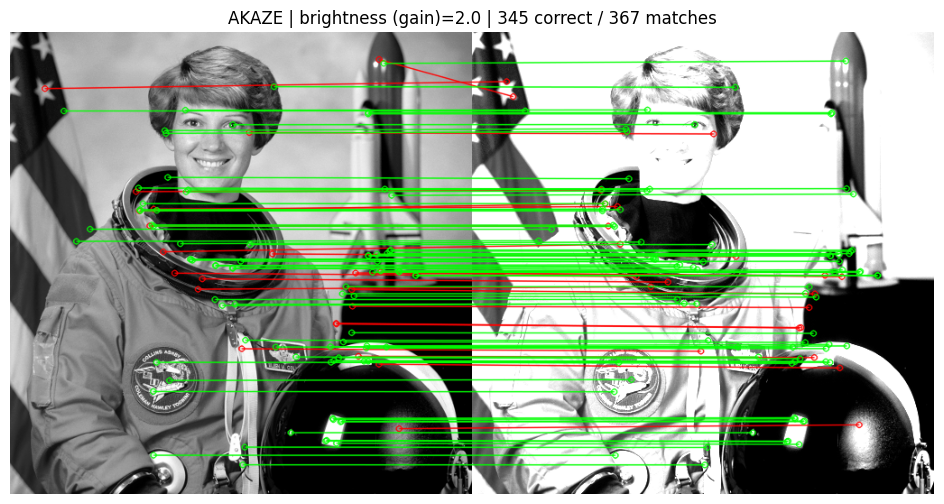

In [ ]:
show_matches("astronaut", "brightness (gain)", 2.0, "AKAZE")

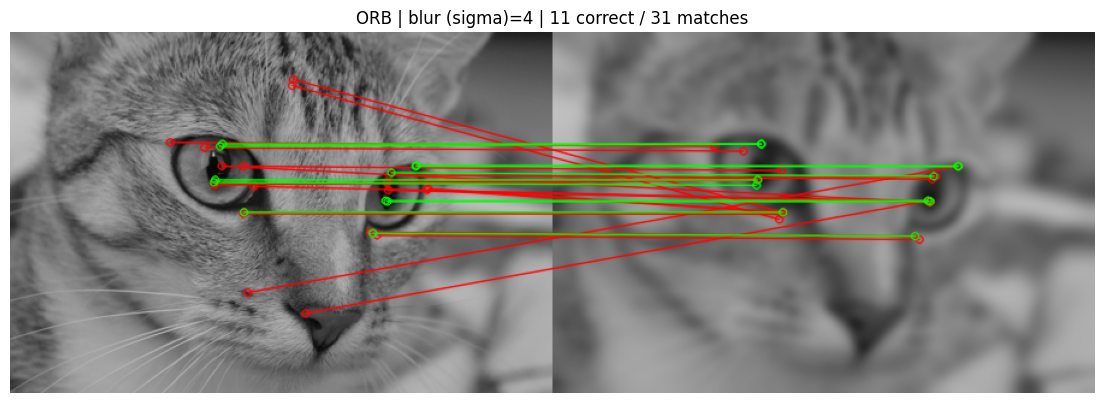

In [ ]:
show_matches("chelsea","blur (sigma)", 4, "ORB")